# Неделя 3. Дообучение BERT (fine-tuning)

Проект: анализ текстов законов и нормативных актов Республики Казахстан (корпус 1-го РК: 8 кодексов, около 3,8 тысячи статей).

**Задача для дообучения.** По тексту статьи определить, к какому кодексу (отрасли права) она относится. Метка берётся из самого корпуса, ручная разметка не нужна. Гражданский кодекс (общая и особенная части) объединён в один класс: деление на части условное, и по тексту отдельной статьи различать их нет смысла. В итоге получается 7 классов.

**Что делает ноутбук**

1. Загружает корпус и делит его на обучающую и тестовую выборки (80/20, со стратификацией по классам).
2. Считает базовую модель 1-го РК: TF-IDF + логистическая регрессия.
3. Оценивает BERT до дообучения: замороженные эмбеддинги + логистическая регрессия.
4. Дообучает BERT на обучающей выборке.
5. Сравнивает результаты «до / после» на отложенной тестовой выборке.
6. Сохраняет модель (понадобится для недели 5) и таблицу предсказаний (понадобится для анализа ошибок на неделе 4).

**Как запускать**

- Если есть видеокарта (например, Google Colab: Runtime, Change runtime type, T4 GPU), ноутбук возьмёт `DeepPavlov/rubert-base-cased`. Обучение займёт около 10-15 минут.
- Если видеокарты нет, ноутбук автоматически возьмёт облегчённую русскую модель `cointegrated/rubert-tiny2` (тоже BERT, но примерно в 6 раз меньше), иначе обучение на процессоре займёт часы.
- Файл `corpus.jsonl` (папка `data/raw` проекта) нужен рядом с ноутбуком. В Colab ноутбук сам попросит его загрузить.

In [2]:
# Установка зависимостей. В Google Colab torch уже установлен.
# Локально torch нужно поставить заранее: pip install torch
%pip install -q transformers scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Настройки и данные

In [3]:
import torch
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available()) # Для CPU-версии будет False, это нормально

# Простейшая проверка тензоров
x = torch.rand(3, 3)
print("Test tensor:\n", x)

Torch version: 2.15.0+cpu
CUDA available: False
Test tensor:
 tensor([[0.0356, 0.0907, 0.5889],
        [0.1945, 0.4777, 0.8988],
        [0.9063, 0.5732, 0.0266]])


In [4]:
import gc
import json
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import (AutoModel, AutoModelForSequenceClassification,
                          AutoTokenizer, get_linear_schedule_with_warmup)

# ---- гиперпараметры (описание каждого - в ячейке перед обучением) ----
SEED = 42
TEST_SIZE = 0.2
EPOCHS = 3
BATCH_SIZE = 16
MAX_LEN = 256
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    MODEL_NAME = "DeepPavlov/rubert-base-cased"
    LEARNING_RATE = 3e-5
else:
    MODEL_NAME = "cointegrated/rubert-tiny2"
    LEARNING_RATE = 1e-4   # у маленькой модели скорость обучения берут выше

NAME_TFIDF = "TF-IDF + LogReg (базовая модель 1-го РК)"
NAME_BEFORE = "BERT до дообучения (замороженные эмбеддинги + LogReg)"
NAME_AFTER = "BERT после fine-tuning"


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print("Устройство:", DEVICE)
print("Модель:", MODEL_NAME)

c:\Users\Acer\Desktop\nlp-legal-project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Устройство: cpu
Модель: cointegrated/rubert-tiny2


In [5]:
# Поиск файла корпуса: рядом с ноутбуком, в папке проекта или загрузка в Colab
CANDIDATES = [Path("data/raw/corpus.jsonl"), Path("../data/raw/corpus.jsonl"),
              Path("corpus.jsonl")]
corpus_path = next((p for p in CANDIDATES if p.exists()), None)

if corpus_path is None:
    try:
        from google.colab import files
        print("Загрузите файл corpus.jsonl (data/raw/corpus.jsonl из проекта)")
        files.upload()
        corpus_path = Path("corpus.jsonl")
    except ImportError:
        raise FileNotFoundError(
            "Не найден corpus.jsonl. Положите его рядом с ноутбуком "
            "или в data/raw/")

with corpus_path.open(encoding="utf-8") as f:
    df = pd.DataFrame([json.loads(line) for line in f if line.strip()])
print("Статей в корпусе:", len(df))

# Класс = название кодекса; две части Гражданского кодекса объединяем
df["label_name"] = df["law"].str.replace(
    r"\s*\((Общая|Особенная) часть\)", "", regex=True)

# Текст для модели: заголовок статьи + её текст
df["input_text"] = df["title"].fillna("") + ". " + df["text"]

# Убираем статьи без содержания («Исключена», «Утратила силу») и точные дубли,
# чтобы одинаковый текст не попал одновременно в train и в test
df = df[df["text"].str.split().str.len() >= 10]
df = df.drop_duplicates("input_text").reset_index(drop=True)
print("После фильтрации:", len(df))
df["label_name"].value_counts()

Статей в корпусе: 3862
После фильтрации: 3763


label_name
Гражданский кодекс РК                            1147
Кодекс РК об административных правонарушениях    1022
Уголовный кодекс РК                               491
Экологический кодекс РК                           420
Кодекс РК о браке (супружестве) и семье           281
Трудовой кодекс РК                                219
Земельный кодекс РК                               183
Name: count, dtype: int64

In [6]:
# Разбиение train/test делается ДО любого обучения, с фиксированным seed.
labels = sorted(df["label_name"].unique())
label2id = {name: i for i, name in enumerate(labels)}
id2label = {i: name for name, i in label2id.items()}
df["label"] = df["label_name"].map(label2id)

train_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Обучающая выборка: {len(train_df)}, тестовая: {len(test_df)}")
print("Пересечение текстов train и test:",
      len(set(train_df["input_text"]) & set(test_df["input_text"])))
print("Классы:", labels)

Обучающая выборка: 3010, тестовая: 753
Пересечение текстов train и test: 0
Классы: ['Гражданский кодекс РК', 'Земельный кодекс РК', 'Кодекс РК о браке (супружестве) и семье', 'Кодекс РК об административных правонарушениях', 'Трудовой кодекс РК', 'Уголовный кодекс РК', 'Экологический кодекс РК']


In [7]:
def compute_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


results = {}

## 2. Базовая модель 1-го РК: TF-IDF + логистическая регрессия

Векторизатор обучается только на обучающей выборке, тест он «не видит».

In [8]:
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), sublinear_tf=True)
X_train = tfidf.fit_transform(train_df["input_text"])
X_test = tfidf.transform(test_df["input_text"])

baseline = LogisticRegression(max_iter=2000)
baseline.fit(X_train, train_df["label"])

results[NAME_TFIDF] = compute_metrics(test_df["label"], baseline.predict(X_test))
print(results[NAME_TFIDF])

{'Accuracy': 0.9548472775564409, 'Precision (macro)': 0.9757342461962925, 'Recall (macro)': 0.9160542920603466, 'F1 (macro)': 0.9426938313756603}


## 3. BERT до дообучения

Предобученная модель применяется как есть: она превращает каждую статью в вектор (среднее по токенам последнего слоя), а поверх этих векторов обучается только простой классификатор. Веса самого BERT не меняются.

In [9]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def encode(texts):
    return tokenizer(list(texts), truncation=True, max_length=MAX_LEN)


class EncodedDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, targets):
        self.enc = encodings
        self.targets = list(targets)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.enc.keys()}
        item["labels"] = self.targets[i]
        return item


def collate(batch):
    # Дополняем токены до длины самого длинного текста в пачке
    targets = torch.tensor([b["labels"] for b in batch])
    feats = [{k: v for k, v in b.items() if k != "labels"} for b in batch]
    out = tokenizer.pad(feats, return_tensors="pt")
    out["labels"] = targets
    return out


train_ds = EncodedDataset(encode(train_df["input_text"]), train_df["label"])
test_ds = EncodedDataset(encode(test_df["input_text"]), test_df["label"])

g = torch.Generator()
g.manual_seed(SEED)
train_loader = torch.utils.data.DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, generator=g)
test_loader = torch.utils.data.DataLoader(
    test_ds, batch_size=32, shuffle=False, collate_fn=collate)
# те же данные без перемешивания - для извлечения эмбеддингов
train_loader_ordered = torch.utils.data.DataLoader(
    train_ds, batch_size=32, shuffle=False, collate_fn=collate)
print("Токенизация готова")

c:\Users\Acer\Desktop\nlp-legal-project\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Acer\.cache\huggingface\hub\models--cointegrated--rubert-tiny2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Токенизация готова


In [10]:
@torch.no_grad()
def extract_embeddings(model, loader):
    model.eval()
    chunks = []
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items() if k != "labels"}
        hidden = model(**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).float()
        pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1)
        chunks.append(pooled.cpu().numpy())
    return np.vstack(chunks)


t0 = time.time()
frozen = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)
emb_train = extract_embeddings(frozen, train_loader_ordered)
emb_test = extract_embeddings(frozen, test_loader)
print(f"Эмбеддинги получены за {time.time() - t0:.0f} с, размер вектора: {emb_train.shape[1]}")

probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
probe.fit(emb_train, train_df["label"])
results[NAME_BEFORE] = compute_metrics(test_df["label"], probe.predict(emb_test))
print(results[NAME_BEFORE])

del frozen
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()

c:\Users\Acer\Desktop\nlp-legal-project\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Acer\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 55/55 [00:00<?, ?it/s]
[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key     

Эмбеддинги получены за 70 с, размер вектора: 312
{'Accuracy': 0.9468791500664011, 'Precision (macro)': 0.9466687761010368, 'Recall (macro)': 0.9396441591271698, 'F1 (macro)': 0.9430905180959978}


## 4. Fine-tuning

**Описание гиперпараметров**

- `EPOCHS = 3`: число полных проходов по обучающей выборке. Для дообучения BERT обычно хватает 2-4 эпох, дальше модель начинает переобучаться.
- `BATCH_SIZE = 16`: сколько статей модель обрабатывает перед одним обновлением весов.
- `LEARNING_RATE`: скорость обучения. 3e-5 для `rubert-base-cased` (стандартное значение для дообучения BERT), 1e-4 для маленькой `rubert-tiny2`. Для дообучения берут малые значения, чтобы не разрушить знания, полученные при предобучении.
- `MAX_LEN = 256`: максимальная длина текста в токенах. Более длинные статьи обрезаются. Это компромисс между полнотой текста и скоростью (у BERT время растёт примерно квадратично с длиной).
- `WARMUP_RATIO = 0.1`: первые 10% шагов скорость обучения плавно растёт от нуля, потом линейно снижается до нуля.
- `WEIGHT_DECAY = 0.01`: небольшая L2-регуляризация против переобучения.
- Оптимизатор AdamW, ограничение нормы градиента 1.0, `SEED = 42` для воспроизводимости.

**Против утечки данных.** Разбиение train/test сделано до обучения; дубли текстов удалены; TF-IDF и логистическая регрессия обучены только на train. Тест после каждой эпохи считается только для графика, лучшая эпоха по нему не выбирается: итоговая оценка берётся после последней эпохи.

In [11]:
set_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(labels), id2label=id2label, label2id=label2id
).to(DEVICE)

no_decay = ["bias", "LayerNorm.weight"]
param_groups = [
    {"params": [p for n, p in model.named_parameters()
                if not any(nd in n for nd in no_decay)], "weight_decay": WEIGHT_DECAY},
    {"params": [p for n, p in model.named_parameters()
                if any(nd in n for nd in no_decay)], "weight_decay": 0.0},
]
optimizer = torch.optim.AdamW(param_groups, lr=LEARNING_RATE)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer, int(WARMUP_RATIO * total_steps), total_steps)


@torch.no_grad()
def predict(model, loader):
    model.eval()
    logits = []
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items() if k != "labels"}
        logits.append(model(**batch).logits.float().cpu())
    probs = torch.softmax(torch.cat(logits), dim=-1)
    return probs.argmax(-1).numpy(), probs.max(-1).values.numpy()


history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    t0 = time.time()
    running = 0.0
    for step, batch in enumerate(train_loader, 1):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        loss = model(**batch).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()
        running += loss.item()
        if step % 50 == 0:
            print(f"  эпоха {epoch}, шаг {step}/{len(train_loader)}, loss {running / step:.4f}")

    preds, _ = predict(model, test_loader)
    m = compute_metrics(test_df["label"], preds)
    history.append({"epoch": epoch, "train_loss": running / len(train_loader),
                    "test_accuracy": m["Accuracy"], "test_f1_macro": m["F1 (macro)"],
                    "time_sec": time.time() - t0})
    print(f"Эпоха {epoch}/{EPOCHS}: train loss {history[-1]['train_loss']:.4f}, "
          f"test accuracy {m['Accuracy']:.4f}, F1 {m['F1 (macro)']:.4f}, "
          f"{history[-1]['time_sec']:.0f} с")

preds, conf = predict(model, test_loader)
results[NAME_AFTER] = compute_metrics(test_df["label"], preds)

Loading weights: 100%|██████████| 55/55 [00:00<00:00, 3542.49it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the ch

  эпоха 1, шаг 50/189, loss 1.7872
  эпоха 1, шаг 100/189, loss 1.3317
  эпоха 1, шаг 150/189, loss 1.0111
Эпоха 1/3: train loss 0.8470, test accuracy 0.9522, F1 0.9453, 319 с
  эпоха 2, шаг 50/189, loss 0.1353
  эпоха 2, шаг 100/189, loss 0.1129
  эпоха 2, шаг 150/189, loss 0.1024
Эпоха 2/3: train loss 0.1000, test accuracy 0.9867, F1 0.9869, 299 с
  эпоха 3, шаг 50/189, loss 0.0453
  эпоха 3, шаг 100/189, loss 0.0433
  эпоха 3, шаг 150/189, loss 0.0388
Эпоха 3/3: train loss 0.0389, test accuracy 0.9894, F1 0.9878, 298 с


## 5. Результаты «до / после»

In [12]:
Path("report").mkdir(exist_ok=True)
results_df = pd.DataFrame(results).T.round(4)
results_df.to_csv("report/week3_results.csv", encoding="utf-8-sig")
results_df

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
TF-IDF + LogReg (базовая модель 1-го РК),0.9548,0.9757,0.9161,0.9427
BERT до дообучения (замороженные эмбеддинги + LogReg),0.9469,0.9467,0.9396,0.9431
BERT после fine-tuning,0.9894,0.9883,0.9874,0.9878


In [13]:
print(classification_report(test_df["label"], preds, target_names=labels,
                            digits=3, zero_division=0))

                                               precision    recall  f1-score   support

                        Гражданский кодекс РК      0.987     0.987     0.987       230
                          Земельный кодекс РК      0.974     1.000     0.987        37
      Кодекс РК о браке (супружестве) и семье      1.000     0.964     0.982        56
Кодекс РК об административных правонарушениях      0.990     0.995     0.993       204
                           Трудовой кодекс РК      0.977     0.977     0.977        44
                          Уголовный кодекс РК      0.990     1.000     0.995        98
                      Экологический кодекс РК      1.000     0.988     0.994        84

                                     accuracy                          0.989       753
                                    macro avg      0.988     0.987     0.988       753
                                 weighted avg      0.989     0.989     0.989       753



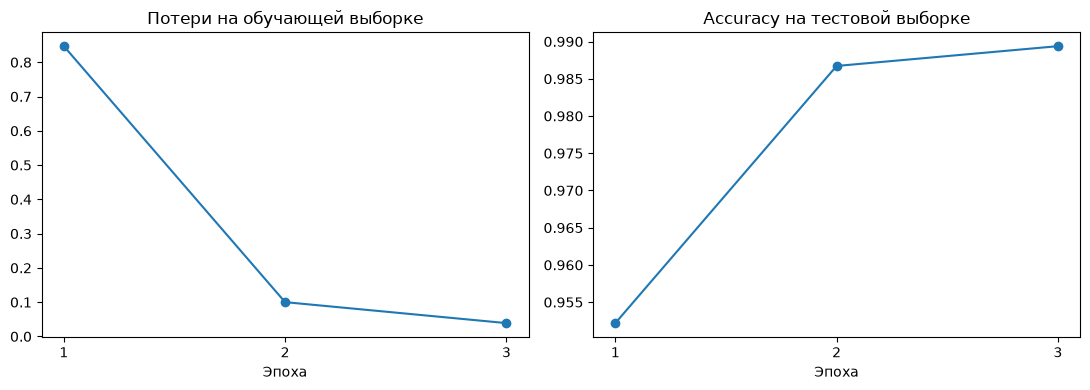

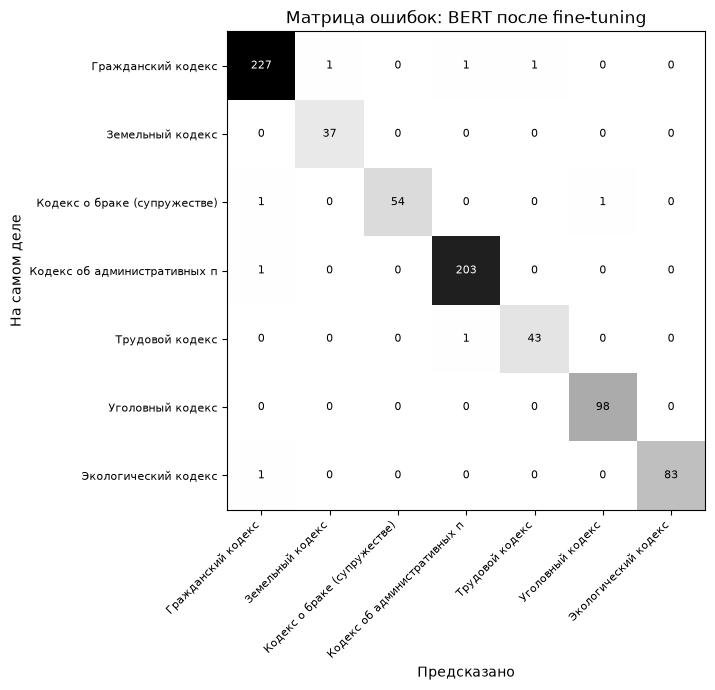

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ep = [h["epoch"] for h in history]
axes[0].plot(ep, [h["train_loss"] for h in history], marker="o")
axes[0].set_title("Потери на обучающей выборке")
axes[0].set_xlabel("Эпоха")
axes[0].set_xticks(ep)
axes[1].plot(ep, [h["test_accuracy"] for h in history], marker="o")
axes[1].set_title("Accuracy на тестовой выборке")
axes[1].set_xlabel("Эпоха")
axes[1].set_xticks(ep)
plt.tight_layout()
plt.savefig("report/week3_training_curves.png", dpi=150)
plt.show()

cm = confusion_matrix(test_df["label"], preds)
short = [l.replace(" Республики Казахстан", "").replace(" РК", "")[:28] for l in labels]
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap="Greys")
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(short, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(short, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
ax.set_xlabel("Предсказано")
ax.set_ylabel("На самом деле")
ax.set_title("Матрица ошибок: BERT после fine-tuning")
plt.tight_layout()
plt.savefig("report/week3_confusion_matrix.png", dpi=150)
plt.show()

In [15]:
# Сохраняем модель (для недели 5), предсказания (для анализа ошибок на неделе 4)
# и параметры запуска
SAVE_DIR = Path("models/bert_legal_cls")
SAVE_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

pd.DataFrame({
    "law": test_df["label_name"],
    "article_number": test_df["article_number"],
    "title": test_df["title"],
    "true": [id2label[i] for i in test_df["label"]],
    "pred": [id2label[i] for i in preds],
    "confidence": conf.round(4),
    "text_preview": test_df["text"].str.slice(0, 300),
}).to_csv("report/week3_test_predictions.csv", index=False, encoding="utf-8-sig")

with open("report/week3_hyperparameters.json", "w", encoding="utf-8") as f:
    json.dump({"model": MODEL_NAME, "device": DEVICE, "epochs": EPOCHS,
               "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
               "max_len": MAX_LEN, "warmup_ratio": WARMUP_RATIO,
               "weight_decay": WEIGHT_DECAY, "seed": SEED,
               "train_size": len(train_df), "test_size": len(test_df)},
              f, ensure_ascii=False, indent=2)
print("Сохранено: models/bert_legal_cls, report/week3_*")

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  7.75it/s]

Сохранено: models/bert_legal_cls, report/week3_*


## 6. Вывод

Ячейка ниже подставляет реальные цифры из этого запуска. Финальный вывод для отчёта перепишите своими словами.

In [16]:
before = results_df.loc[NAME_BEFORE]
after = results_df.loc[NAME_AFTER]
tf = results_df.loc[NAME_TFIDF]
gain = (after["Accuracy"] - before["Accuracy"]) * 100
errors = int((preds != test_df["label"].values).sum())

print(f"Модель: {MODEL_NAME}; обучающих статей {len(train_df)}, тестовых {len(test_df)}.")
print(f"До fine-tuning: accuracy {before['Accuracy']:.3f}, F1 {before['F1 (macro)']:.3f}.")
print(f"После fine-tuning: accuracy {after['Accuracy']:.3f}, F1 {after['F1 (macro)']:.3f}.")
print(f"Прирост accuracy: {gain:+.1f} п.п.; на тесте ошибок: {errors} из {len(test_df)}.")
print(f"Базовая модель TF-IDF + LogReg: accuracy {tf['Accuracy']:.3f}, F1 {tf['F1 (macro)']:.3f}.")
if after["Accuracy"] > tf["Accuracy"]:
    print("Дообученный BERT превзошёл базовую модель 1-го РК.")
else:
    print("Дообученный BERT не превзошёл TF-IDF: в этой задаче кодекс легко узнаётся "
          "по лексике (термины трудового, земельного, уголовного права), поэтому "
          "простая модель на словах уже работает сильно.")

Модель: cointegrated/rubert-tiny2; обучающих статей 3010, тестовых 753.
До fine-tuning: accuracy 0.947, F1 0.943.
После fine-tuning: accuracy 0.989, F1 0.988.
Прирост accuracy: +4.2 п.п.; на тесте ошибок: 8 из 753.
Базовая модель TF-IDF + LogReg: accuracy 0.955, F1 0.943.
Дообученный BERT превзошёл базовую модель 1-го РК.
